# 10-1. CRPS 방식 비교 (원 스케일 / GARCH / 자체 구간)

GARCH 원 스케일 자체 구간(정규분포)의 CRPS를 네 가지로 계산해 비교한다(예측은 같고 계산법만 다름).
1. 정확값 `crps_gaussian` / 2. 7분위 값을 앙상블로 `crps_ensemble` / 3. 기존 `crps7` / 4. 정규 분위수 500개를 앙상블로 `crps_ensemble`(난수 없음)

`var_std`로 나누고 88개(22 origin x h=1~4)를 평균한다.

In [1]:
import numpy as np
import pandas as pd
import properscoring as ps
from scipy import stats
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

LEVELS = np.array([0.1, 0.2, 0.3, 0.5, 0.7, 0.8, 0.9])
N_ENS = 500
U = stats.norm.ppf((np.arange(N_ENS) + 0.5) / N_ENS)      # 정규 분위수 N개 (표준정규)
raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
vals = raw[["quarter", "X3_l1"]].dropna()["X3_l1"].values.astype(float)
var_std = vals.std()                    # 9시리즈와 같은 정의(numpy, ddof=0)

d = pd.read_pickle("../cache/cache_96_garch_orig_df.pkl")
s = d[d["방식"] == "자체"].reset_index(drop=True)      # 88행: origin, h, fc(μ), actual, sigma_model(σ_h)
print(len(s), "행, var_std =", round(var_std, 3))

88 행, var_std = 282.627


In [2]:
def pinball(q, y, tau):
    return np.where(y >= q, (y - q) * tau, (q - y) * (1 - tau))

def crps7(q7, y):
    return 2 * np.mean([pinball(q7[k], y, LEVELS[k]) for k in range(7)])

rows = []
for r in s.itertuples():
    mu, sig, y = r.fc, r.sigma_model, r.actual
    q7 = mu + sig * stats.norm.ppf(LEVELS)                   # 정규분포의 7분위 값
    rows.append({"origin": r.origin, "h": r.h,
                 "1. 정확값(crps_gaussian)": ps.crps_gaussian(y, mu=mu, sig=sig) / var_std,
                 "2. 7분위를 앙상블로(crps_ensemble)": ps.crps_ensemble(y, q7) / var_std,
                 "3. 기존 crps7": crps7(q7, y) / var_std,
                 "4. 정규 분위수 앙상블(N=500)": ps.crps_ensemble(y, mu + sig * U) / var_std})
res = pd.DataFrame(rows)
cols = [c for c in res.columns if c[0] in "1234"]
chk = np.abs(res["3. 기존 crps7"] - s["CRPS(7분위)"]).max()
print("기존 캐시의 CRPS(7분위)와 3번 값의 최대 차이:", chk)

기존 캐시의 CRPS(7분위)와 3번 값의 최대 차이: 0.0


## 1. 전체 평균

1번(정확값) 대비 차이를 본다.

In [3]:
per_origin = res.groupby(["origin", "h"])[cols].mean().groupby("origin").mean()
summ = per_origin.mean().to_frame("평균 CRPS")
summ["1번 대비(%)"] = 100 * (summ["평균 CRPS"] / summ.loc["1. 정확값(crps_gaussian)", "평균 CRPS"] - 1)
display(summ.round(4))

,평균 CRPS,1번 대비(%)
1. 정확값(crps_gaussian),0.5794,0.0000
2. 7분위를 앙상블로(crps_ensemble),0.5915,2.0888
3. 기존 crps7,0.5892,1.6927
4. 정규 분위수 앙상블(N=500),0.5795,0.0030


## 2. h별·예측별 비교

In [4]:
display(res.groupby("h")[cols].mean().round(4))
rel = pd.DataFrame({c: 100 * (res[c] / res["1. 정확값(crps_gaussian)"] - 1) for c in cols[1:]})
print("88개 예측별 1번 대비 차이(%) 요약:")
display(rel.describe().loc[["mean", "min", "50%", "max"]].round(2))
print("88개 값의 상관(Pearson) / 순위상관(Spearman):")
display(pd.DataFrame({"Pearson": res[cols].corr().iloc[0, 1:], "Spearman": res[cols].corr(method="spearman").iloc[0, 1:]}).round(4))

,1. 정확값(crps_gaussian),2. 7분위를 앙상블로(crps_ensemble),3. 기존 crps7,4. 정규 분위수 앙상블(N=500)
h,,,,
1,0.2852,0.2922,0.2910,0.2852
2,0.5056,0.5157,0.5137,0.5056
3,0.6870,0.7043,0.7016,0.6871
4,0.8399,0.8540,0.8506,0.8399


88개 예측별 1번 대비 차이(%) 요약:


,2. 7분위를 앙상블로(crps_ensemble),3. 기존 crps7,4. 정규 분위수 앙상블(N=500)
mean,3.89,3.21,0.00
min,-4.61,-5.25,-0.00
50%,2.13,1.86,0.00
max,16.96,15.70,0.01


88개 값의 상관(Pearson) / 순위상관(Spearman):


,Pearson,Spearman
2. 7분위를 앙상블로(crps_ensemble),0.9995,0.9952
3. 기존 crps7,0.9995,0.9955
4. 정규 분위수 앙상블(N=500),1.0000,1.0000


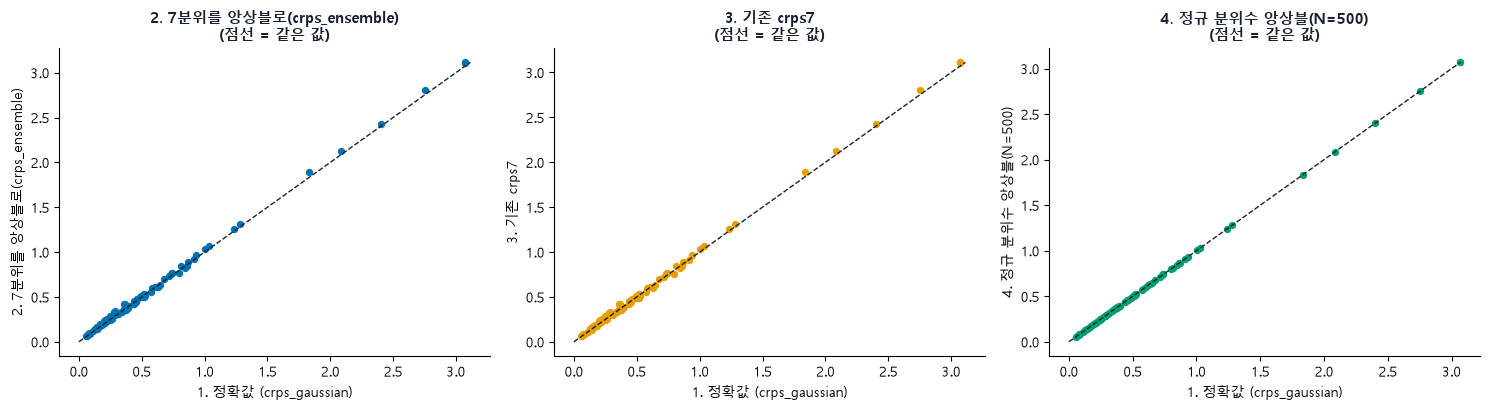

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, c, col in zip(axes, cols[1:], ["#0072B2", "#E69F00", "#009E73"]):
    ax.scatter(res[cols[0]], res[c], color=col, s=18)
    m = max(res[cols[0]].max(), res[c].max())
    ax.plot([0, m], [0, m], color="#172033", linestyle="--", linewidth=1)
    ax.set_xlabel("1. 정확값 (crps_gaussian)")
    ax.set_ylabel(c)
    ax.set_title(f"{c}\n(점선 = 같은 값)", fontsize=11, fontweight="bold", color="#172033")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

## 3. 결론

**정규 분위수 앙상블(4번)은 정확값(1번)과 같고, 7분위 근사(2·3번)는 약 2% 높다.**

| 방식 | 평균 CRPS | 정확값 대비 |
|---|---|---|
| 1. 정확값 | 0.5794 | - |
| 2. 7분위를 앙상블로 | 0.5915 | +2.1% |
| 3. 기존 `crps7` | 0.5892 | +1.7% |
| 4. 정규 분위수 앙상블 | 0.5795 | +0.003% |

- 4번은 88개 예측 모두 1번과 차이가 0.01% 이하라서, 자체 구간에도 `crps_ensemble`을 쓸 수 있다.
- 7분위 근사는 높게 나오지만 순서는 거의 같다(순위상관 0.995).
- 한계: GARCH 원 스케일 자체 구간 한 조합만 확인했다.